# 🔶 Test Set I

## 🔹 Data preparation

> Note: some of the data in `training set` and `Test Set I` are from HGMD professional, so we can't redistribute the data.

In [ ]:
# load packages
from sklearn.metrics import roc_auc_score , average_precision_score
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

# Prediction result from other VEPs
ALL_PRED_PATH = "./benchmarks/test-set-I/"
pred_data = pd.read_csv(f"{ALL_PRED_PATH}/pred.2600.all.txt", sep='\t')
pred_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2600 entries, 0 to 2599
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   variant38   2600 non-null   object 
 1   label       2600 non-null   int64  
 2   CADD        2599 non-null   float64
 3   DANN        2596 non-null   float64
 4   EIGEN       2269 non-null   float64
 5   FATHMM-MKL  2596 non-null   float64
 6   FATHMM-XF   2291 non-null   float64
 7   CAPICE      2427 non-null   float64
 8   TraP        2590 non-null   float64
 9   PhD-SNPg    2595 non-null   float64
 10  GPN-MSA     2599 non-null   float64
 11  fitCons     2301 non-null   float64
 12  EnDSM       2595 non-null   float64
 13  frDSM       2589 non-null   float64
 14  PrDSM       2574 non-null   float64
 15  usDSM       2595 non-null   float64
 16  SilVA       2587 non-null   float64
 17  seDSM       2595 non-null   float64
 18  SynScore    238 non-null    float64
dtypes: float64(17), int64(1), o

In [ ]:
# Compute maximum common subset prediction results
def subset_metrics(df, pred_cols=None):
    """
    Desc:
        Compute subset comparison results
    Args:
        df: dataframe containing prediction scores
        pred_cols: columns to be compared
    """
    df = df[['label'] + pred_cols]
    df = df.dropna()
    print(f"[INFO] Subset amount: {len(df)}")
    auc_compare_list, aupr_compare_list = [], []
    y_label = df["label"].tolist()
    if 'GPN-MSA' in df.columns:
        df['GPN-MSA'] = -df['GPN-MSA']
    df = df[pred_cols]
    for col in df.columns:
        auc_compare_list.append(roc_auc_score(y_label, df[col]))
        aupr_compare_list.append(average_precision_score(y_label, df[col]))
    df_result = pd.DataFrame({'VEP': list(df.columns), 
                              'AUC': auc_compare_list,
                              'AUPR': aupr_compare_list})
    return df_result

In [ ]:
# GPN-CaLM-newBio
transyn = pd.read_csv("./benchmarks/test-set-I/TranSyn.pred.txt", sep='\t', usecols=['vid', 'pred_prob'])
transyn.columns = ['variant38', 'TranSyn']
# Merge prediction scores
pred = transyn.merge(pred_data, how='left', left_on='variant38', right_on='variant38', suffixes=('', '_m'))
tools = ['CADD', 'TraP', 'SilVA', 'seDSM', 'SynScore', 'TranSyn']  # Top methods
pred = pred[['variant38', 'label'] + tools]
# Get prediction performance on the subset
subset_metrics_df = subset_metrics(df=pred, pred_cols=tools)

[INFO] Subset amount: 233


## 🔹 Figure 2A 2B - AUC Curve | HSR Region

## 🔹 Figure 2C - Spearman Analysis

(<Figure size 700x700 with 2 Axes>, <Axes: >)

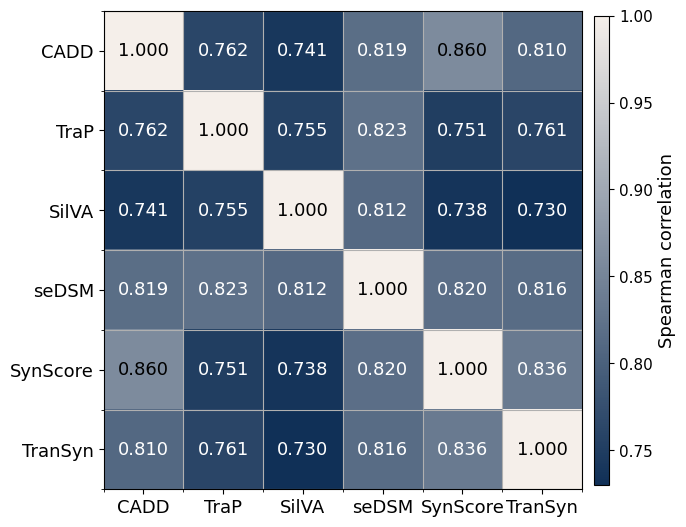

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def plot_spearman_heatmap(df, figsize=(7, 7), show_value=False):
    if 'GPN-MSA' in df.columns:
        df['GPN-MSA'] = -df['GPN-MSA']
    # 1. Spearman correlation
    corr = df.corr(method='spearman')

    # 2. Custom colormap
    cmap = LinearSegmentedColormap.from_list(
        "custom_cmap",
        # ["#da4c36", "#fff", "#3fadc4"]
        ["#103057", "#F5EFEA"] # #103057 #152e8b #103057
        # ["#103057", "#92ccd7"] 
    )

    # 3. Plotting
    vmin = corr.values.min()
    vmax = 1.0
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(
        corr.values,
        cmap=cmap,
        vmin=vmin,
        vmax=1
    )

    # 4. Set axes
    ax.set_xticks(np.arange(len(corr.columns)))
    ax.set_yticks(np.arange(len(corr.columns)))

    ax.set_xticklabels(corr.columns, fontsize=13)
    ax.set_yticklabels(corr.columns, fontsize=13)

    # 5. Add grid lines
    ax.set_xticks(np.arange(len(corr.columns)+1) - 0.5, minor=True)
    ax.set_yticks(np.arange(len(corr.columns)+1) - 0.5, minor=True)
    ax.grid(which='minor')
    ax.set_aspect('equal')

    # 6. Display values
    if show_value:
        # Normalization consistent with imshow
        norm = plt.Normalize(vmin=vmin, vmax=vmax)
        for i in range(corr.shape[0]):
            for j in range(corr.shape[1]):
                value = corr.iloc[i, j]
                # Get background color
                rgba = cmap(norm(value))
                # Calculate luminance (perceptual luminance)
                r, g, b, _ = rgba
                luminance = 0.299*r + 0.587*g + 0.114*b
                # Choose text color based on luminance
                text_color = "white" if luminance < 0.5 else "black"
                ax.text(
                    j,
                    i,
                    f"{value:.3f}",
                    ha='center',
                    va='center',
                    fontsize=13,
                    color=text_color
                )
    # 7. Colorbar
    cbar = plt.colorbar(
        im,
        ax=ax,
        shrink=0.7,  
        aspect=30,   
        pad=0.02      
    )
    cbar.set_label("Spearman correlation", fontsize=13)
    cbar.ax.tick_params(labelsize=11)
    plt.tight_layout()
    return fig, ax


tools = ['CADD', 'TraP', 'SilVA', 'seDSM', 'SynScore', 'TranSyn']
tools_df = result_data_nona[tools]
tools_df.head()
plot_spearman_heatmap(df=tools_df, show_value=True)

# 🔶 Test Set II

## 🔹 Figure 2E - AUPR Curve

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import warnings
warnings.filterwarnings("ignore")


def retrieve_variant(df, chrom_col, pos_col, ref_col, alt_col, prefix=''):
    """Generate variant ID (vid)"""
    variant = [f'{prefix}{chro}_{pos}_{ref}/{alt}' for chro, pos, ref, alt in zip(df[chrom_col], df[pos_col], df[ref_col], df[alt_col])]
    return variant


def subset_metrics(df, pred_cols=None):
    """Compute subset comparison results"""
    sub_columns = ['variant38', 'label'] + pred_cols
    df = df[sub_columns]
    print(df.info())
    df = df.dropna()
    print(f"[INFO] Subset amount: {len(df)}")
    auc_compare_list, aupr_compare_list = [], []
    y_label = df["label"].tolist()
    if 'GPN-MSA' in df.columns:
        df['GPN-MSA'] = -df['GPN-MSA']
    df = df[pred_cols]
    for col in df.columns:
        auc_compare_list.append(roc_auc_score(y_label, df[col]))
        aupr_compare_list.append(average_precision_score(y_label, df[col]))
    df_result = pd.DataFrame({'VEP': list(df.columns), 
                              'AUC': auc_compare_list,
                              'AUPR': aupr_compare_list})
    return df_result


def merge_data(path, df_meta):
    """Merge prediction scores"""
    if 'Variant38' in df_meta.columns:
        df_meta.rename(columns={'Variant38': 'variant38'}, inplace=True)
    usecols_com = ['variant38', 'cadd_phred', 'dann_score', 'eigen_score',
                   'fathmm_mkl_score', 'fathmm_xf_score', 'capice_score', 
                   'trap_score', 'phd_snpg_score', 'gpn_msa_score', 'integrated_fitcons_score']
    df_pan = pd.read_csv(f"{path}/Generic_deleteriousness_scores.csv", usecols=usecols_com)
    usecols_syn = ['endsm_score', 'frdsm_score', 'prdsm_score', 'usdsm_score', 
                   'sedsm_score', 'sliva_score', 'variant38']
    df_syn = pd.read_csv(f"{path}/Synonymous_specific_deleteriousness_scores.csv", usecols=usecols_syn)
    df_synscore = pd.read_csv(f"{path}/Basic_Variant_Information.csv", usecols=['Variant38', 'synscore'])
    df_synscore.rename(columns={'Variant38': 'variant38', 'synscore': 'SynScore'}, inplace=True)
    df_synscore.drop_duplicates(subset='variant38', inplace=True)

    df_meta = df_meta.merge(df_pan, how='left', left_on='variant38', right_on='variant38', suffixes=('', '_m'))
    df_meta = df_meta.merge(df_syn, how='left', left_on='variant38', right_on='variant38', suffixes=('', '_m'))
    df_meta = df_meta.merge(df_synscore, how='left', left_on='variant38', right_on='variant38', suffixes=('', '_m'))

    df_meta.columns = ['variant38', 'label', 'CADD', 'DANN', 'EIGEN', 'FATHMM-MKL', 'FATHMM-XF', 'CAPICE', 'TraP', 'PhD-SNPg', 'GPN-MSA', 'fitCons', 'EnDSM', 'frDSM', 'PrDSM', 'usDSM', 'SilVA', 'seDSM', 'SynScore']
    return df_meta

In [ ]:
PRED_PATH = "./benchmarks/test-set-II/"
# meta info
df_meta = pd.read_csv(f"{PRED_PATH}/Clinvar.202601-202504.462.txt", sep='\t', usecols=['Variant38', 'label'])

# other vep
pred_data = merge_data(path=f"{PRED_PATH}/", df_meta=df_meta)

# transyn pred
transyn_df = pd.read_csv(f"{PRED_PATH}/Clinvar.202601-202504.462.txt", sep='\t', usecols=['vid', 'pred_prob'])
transyn_df.columns = ['variant38', 'TranSyn']

pred_data = pred_data.merge(transyn_df, how='left', left_on='variant38', right_on='variant38', suffixes=('', '_m'))
print(f"[INFO] Merge pred score: {len(pred_data)}...")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from sklearn.metrics import precision_recall_curve, average_precision_score


def plot_aupr_curve(
	df,
	label_col,
	methods,
	best_n=2,
	figsize=(7, 6)
):
	"""Plot AUPR (Precision-Recall Curve) comparison"""
	df.dropna(inplace=True)
	print(f"[INFO] print subset: {len(df)}")
	y_true = df[label_col].astype(int).values
	fig, ax = plt.subplots(1, 1, figsize=figsize)
	aupr_scores = {}
	pr_data = {}

	# compute PR curves
	for m in methods:
		y_score = df[m].astype(float).values

		precision, recall, _ = precision_recall_curve(y_true, y_score)
		ap = average_precision_score(y_true, y_score)

		aupr_scores[m] = ap
		pr_data[m] = (recall, precision)

	# ranking
	sorted_methods = sorted(aupr_scores.items(), key=lambda x: x[1], reverse=True)
	top_methods = [x[0] for x in sorted_methods[:best_n]]

	# styling
	colors = {m: "#AAAAAA" for m in methods}
	highlight_colors = ["#103057", "#92ccd7"]
	for i, m in enumerate(top_methods):
		colors[m] = highlight_colors[i % len(highlight_colors)]

	linestyles = {m: "-" if m in top_methods else "--" for m in methods}

	markers = ['o', 's', '^', 'D', '>', 'P', '*', 'X', 'p', 'h']
	marker_map = {
		m: markers[i % len(markers)] if m not in top_methods else None
		for i, m in enumerate(methods)
	}

	# plot
	for m, _ in sorted_methods:
		recall, precision = pr_data[m]
		marker = marker_map[m]

		if marker:
			ax.plot(
				recall, precision,
				color=colors[m],
				linestyle=linestyles[m],
				marker=marker,
				markevery=0.1,
				markersize=7,
				markerfacecolor=to_rgba(colors[m], alpha=0.3),
				markeredgecolor="#444",
				linewidth=1,
				label=f"{m} (AUPR={aupr_scores[m]:.3f})"
			)
		else:
			ax.plot(
				recall, precision,
				color=colors[m],
				linestyle=linestyles[m],
				linewidth=1.5,
				label=f"{m} (AUPR={aupr_scores[m]:.3f})"
			)

	# axis config
	ax.set_xlabel("Recall", fontsize=15)
	ax.set_ylabel("Precision", fontsize=15)
	ax.set_xticks(np.arange(0, 1.1, 0.1))
	ax.set_yticks(np.arange(0, 1.1, 0.1))
	ax.tick_params(axis='both', labelsize=15)
	for spine in ax.spines.values():
		spine.set_linewidth(0.5)
	ax.legend(loc="lower left", fontsize=14, ncols=1, frameon=False)
	plt.tight_layout()
	plt.show()
	return aupr_scores

top_tools = ['CADD', 'TraP', 'SilVA', 'seDSM', 'SynScore', 'TranSyn']

aupr_scores = plot_aupr_curve(
	df=pred_data[['label'] + top_tools],
	label_col="label",
	methods=top_tools,
	figsize=(6, 5.5)
)

## 🔹 Figure 2F - Recall@Top k

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_rgba


def recall_at_k(y_true, y_score, k):
    """
    y_true: array-like (0/1)
    y_score: prediction score
    k: int, top-k
    """
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    idx = np.argsort(y_score)[::-1]
    topk = y_true[idx[:k]]

    total_pos = y_true.sum()
    if total_pos == 0:
        return 0.0

    return topk.sum() / total_pos


def recall_at_percent(y_true, y_score, percent=0.01):
    y_true = np.asarray(y_true)
    n = len(y_true)
    k = max(1, int(n * percent))
    return recall_at_k(y_true, y_score, k)


def plot_recall_at_percent(
        df,
        label_col,
        methods,
        colors,
        percents
):

    y_true = df[label_col].values
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for m, c in zip(methods, colors):
        y_score = df[m].values
        y = [
            recall_at_percent(y_true, y_score, p)
            for p in percents
        ]
        print(f"=== Methods: {m} ===")
        print(f"=== y: {y} ===")
        # semi-transparent marker
        marker_color = list(to_rgba(c))
        marker_color[3] = 0.5   # marker alpha
        # TranSyn highest layer
        if m == "TranSyn":
            z = 10
            lw = 1
        else:
            z = 5
            lw = 1

        ax.plot(
            percents,
            y,
            # line
            color=c,
            linewidth=lw,
            # marker
            marker='o',
            markersize=8,
            markerfacecolor=marker_color,
            markeredgecolor=marker_color,
            label=m,
            # z-order level
            zorder=z
        )

    # axes
    ax.set_xlabel("Top fraction (%)", fontsize=15)
    ax.set_ylabel("Recall", fontsize=15)
    ax.set_yticks(np.arange(0, 1.1, 0.1))
    ax.set_xticks(
        ticks=np.arange(0, 0.22, 0.02),
        labels=np.arange(0, 22, 2)
    )
    # ax.set_xticks(
    #   ticks=np.arange(0, 0.11, 0.02),
    #   labels=np.arange(0, 11, 2)
    # )
    ax.set_ylim(-0.05, 0.95)
    ax.set_xlim(-0.005, 0.22)
    # ax.set_xlim(-0.005, 0.11)
    ax.tick_params(axis='both', labelsize=15)

    # borders
    for spine in ax.spines.values():
        spine.set_linewidth(0.5)

    # legend
    ax.legend(
        fontsize=15,
        frameon=False
    )

    plt.tight_layout()
    plt.show()


# Function call section
top_tools = [
    'TranSyn',
    'SynScore',
    'seDSM',
    'TraP',
    'SilVA',
    'CADD'
]
colors = [
    '#103057',
    '#5d6a88',
    '#a5abbb',
    '#fcb4a6',
    '#f77460',
    '#e70f1e'
]
colors.reverse()
df = pred_data[['label'] + top_tools]

label_col = 'label'
methods = top_tools

percents = list(np.linspace(0.01, 0.2, 20)) # NOTE Change here

plot_recall_at_percent(
    df,
    label_col,
    methods,
    colors,
    percents
)